# Task 2 — Trends without spaghetti

Completed Week 1 assignment. Every chart is followed by its design justification and interpretation.

**Run:** Python 3 with `pandas`, `numpy`, `matplotlib`, `seaborn`, and `IPython`. Use **Restart Kernel and Run All**. The original CSV is embedded, so no network or extra data files are needed.

**Data source:** [gapminder.csv](https://raw.githubusercontent.com/resbaz/r-novice-gapminder-files/master/data/gapminder-FiveYearData.csv), downloaded 30 September 2026 using the assignment script's source URL. These are historical teaching datasets, not current-world estimates.

**Chart policy:** finding-led titles, no dual y-axes, zero-based bars, meaningful colour and selective labels. The deliberately messy Task 2 chart is the required counterexample.

In [1]:
import base64, zlib, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
BLUE, ORANGE, GREEN = "#0072B2", "#D55E00", "#009E73"
def finish(fig, note):
    fig.text(0.01, 0.012, note, fontsize=9, color="#555555")
    fig.tight_layout(rect=(0, 0.065, 1, 0.96))
    plt.show()

# Compressed CSV snapshot from the source linked above.
# Replace df with pd.read_csv("data/gapminder.csv") to use your local assignment file.
CSV_B64 = (
    '...'
    'lKRc4jdA6tt+4/8D1BFGKQ=='
)
df = pd.read_csv(io.BytesIO(zlib.decompress(base64.b64decode(CSV_B64))))
assert len(df) == 1704
print("Shape:", df.shape)
display(df.head())
display(df.isna().sum().rename("missing rows").to_frame())

Shape: (1704, 6)


,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333.0,Asia,28.801,779.445314
1,Afghanistan,1957,9240934.0,Asia,30.332,820.853030
2,Afghanistan,1962,10267083.0,Asia,31.997,853.100710
3,Afghanistan,1967,11537966.0,Asia,34.020,836.197138
4,Afghanistan,1972,13079460.0,Asia,36.088,739.981106


,missing rows
country,0
year,0
pop,0
continent,0
lifeExp,0
gdpPercap,0


In [2]:
assert df.isna().sum().sum() == 0
assert df.country.nunique() == 142 and df.year.nunique() == 12
assert not df.duplicated(['country','year']).any()
assert df.gdpPercap.gt(0).all()

## 1. Required bad chart: all 142 country lines and legend
This is intentionally kept as a counterexample, including the unusable legend requested in the task.

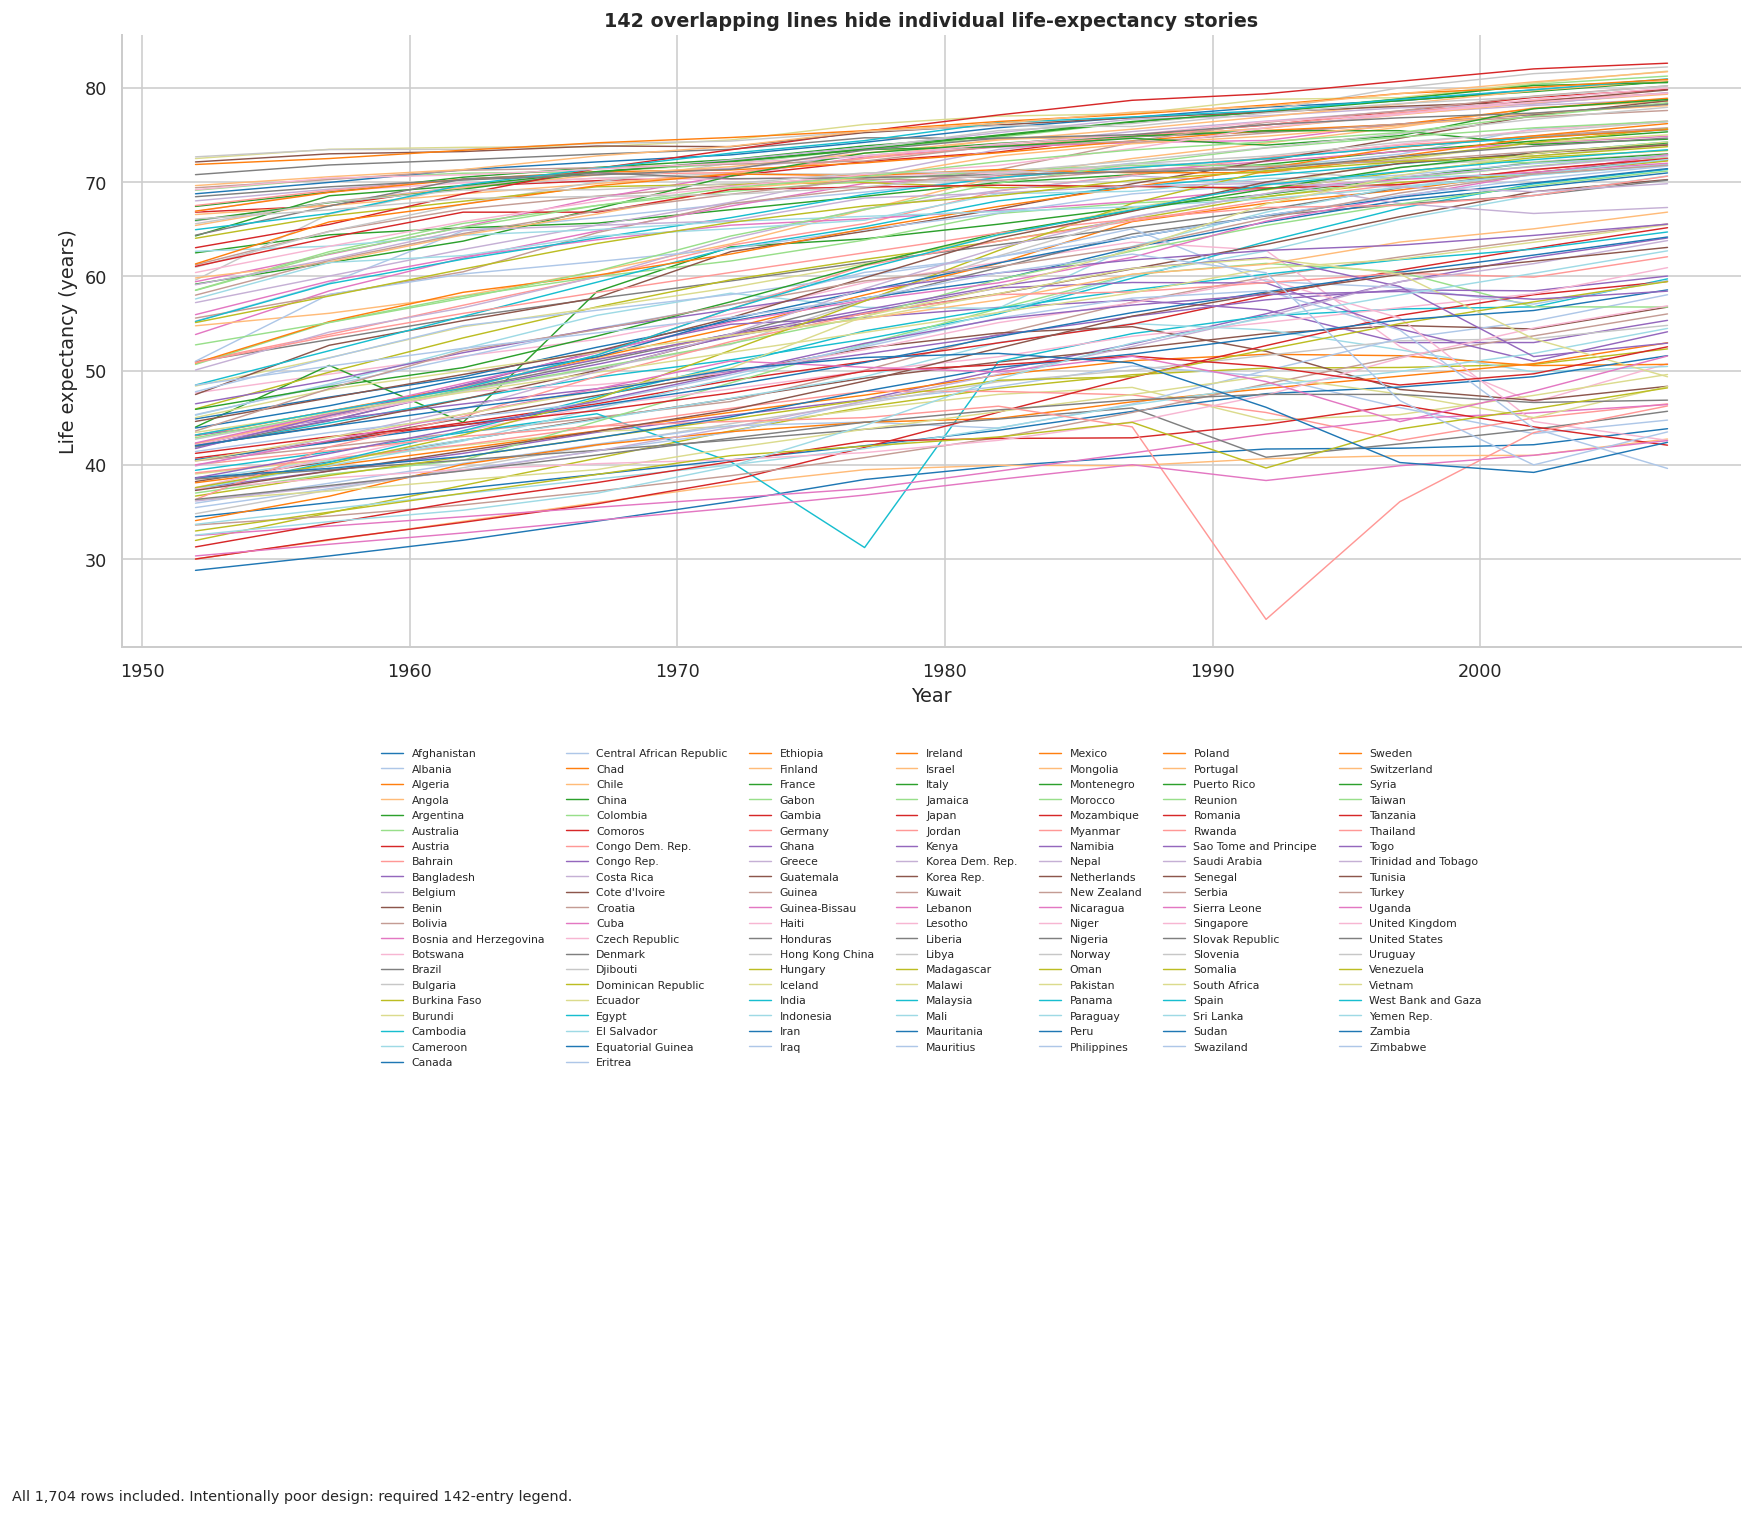

In [3]:
fig = plt.figure(figsize=(16, 14))
ax = fig.add_axes([.07, .55, .88, .38])
for i, (country, g) in enumerate(df.groupby('country')):
    ax.plot(g.year, g.lifeExp, lw=.9, color=plt.cm.tab20(i % 20), label=country)
ax.set(title='142 overlapping lines hide individual life-expectancy stories',
       xlabel='Year', ylabel='Life expectancy (years)')
ax.legend(ncol=7, fontsize=6.8, loc='upper center', bbox_to_anchor=(.5, -.15), frameon=False)
fig.text(.01,.02,'All 1,704 rows included. Intentionally poor design: required 142-entry legend.',fontsize=9)
plt.show()

**Why this chart is retained:** A line is suitable for repeated country observations over ordered time, but placing all lines and a 142-entry legend together defeats comparison. Lines overlap, colours repeat, crossing paths are hard to follow, the legend requires constant lookups, and the large legend competes with the data. It is difficult to find a specific country or distinguish outliers. The colours convey no reliable country identity. Straight segments also hide what happened between five-year observations. This chart deliberately violates the usable-legend rule as required by the assignment.

## 2(a). Aggregate by continent
Use an **unweighted mean of countries**, not a population-weighted global-person average.

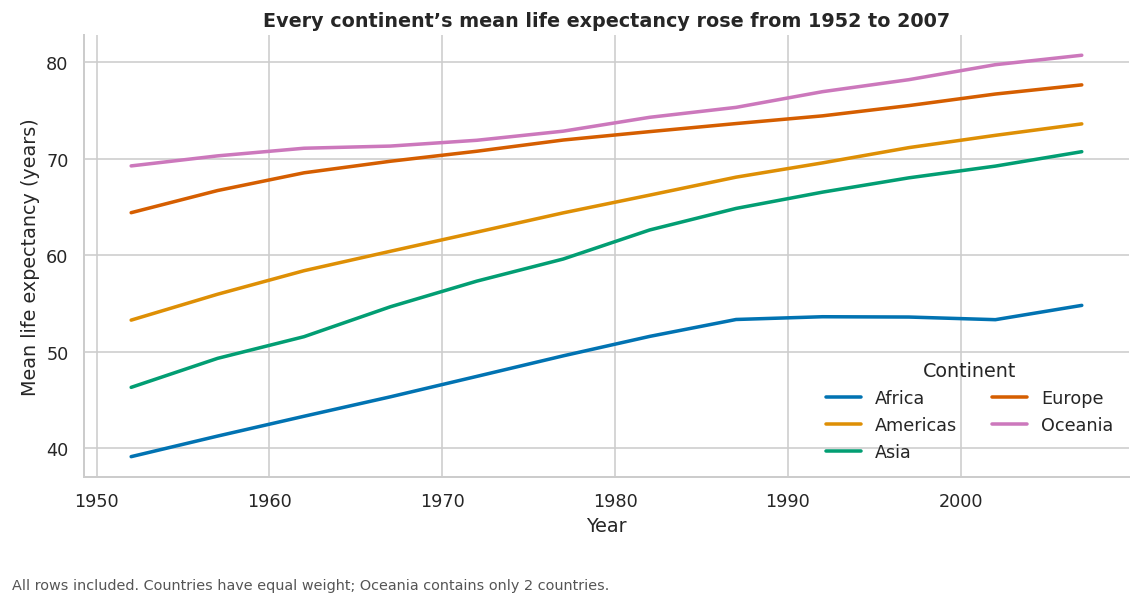

In [4]:
continent_mean = df.groupby(['continent','year'], as_index=False).lifeExp.mean()
continent_order = ['Africa','Americas','Asia','Europe','Oceania']
colors = dict(zip(continent_order, sns.color_palette('colorblind', 5)))
fig, ax = plt.subplots(figsize=(10, 5.5))
for continent in continent_order:
    g = continent_mean[continent_mean.continent.eq(continent)]
    ax.plot(g.year, g.lifeExp, lw=2.2, color=colors[continent], label=continent)
ax.set(title='Every continent’s mean life expectancy rose from 1952 to 2007',
       xlabel='Year', ylabel='Mean life expectancy (years)')
ax.legend(title='Continent', frameon=False, ncol=2)
finish(fig, 'All rows included. Countries have equal weight; Oceania contains only 2 countries.')

**Why lines:** Five lines reveal the broad time trends without excessive overlap, and colour identifies continent. The chart shows rising regional averages and persistent regional differences. Averaging hides country-specific reversals and variation within each continent; Oceania’s two-country mean is not a broad regional sample.

## 2(b). Highlight three countries
Japan shows sustained improvement, Rwanda shows a severe reversal, and South Africa shows a late decline in this dataset.

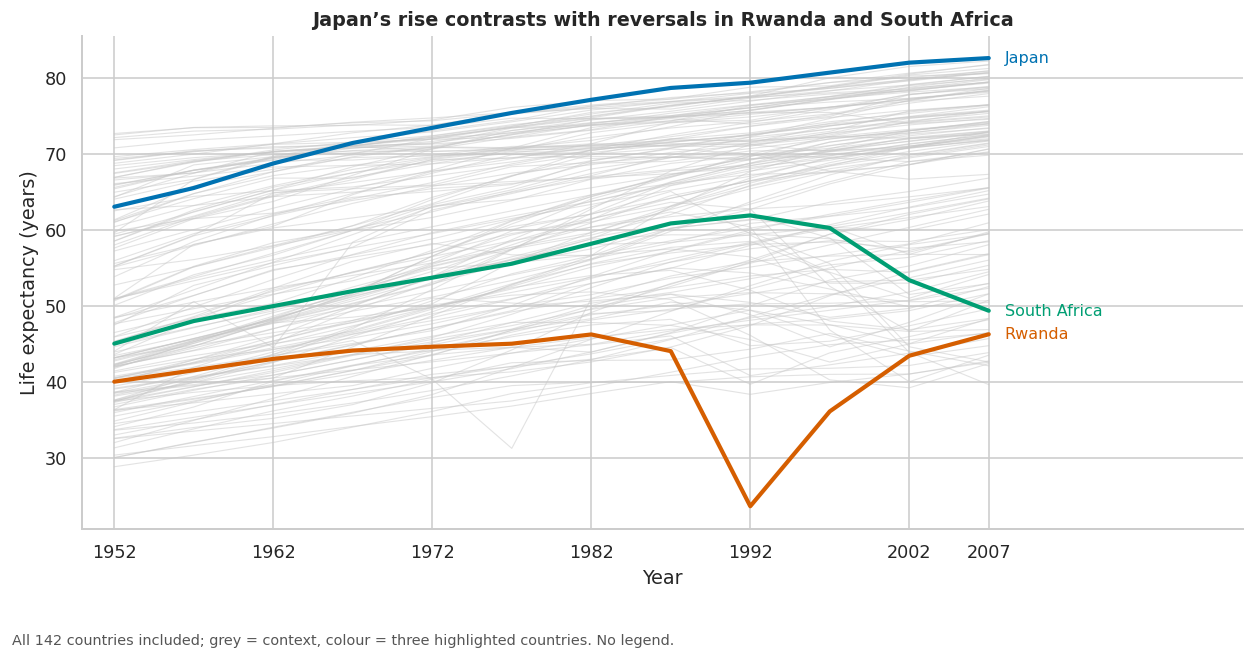

In [5]:
selected = {'Japan': BLUE, 'Rwanda': ORANGE, 'South Africa': GREEN}
fig, ax = plt.subplots(figsize=(11, 6))
for country, g in df.groupby('country'):
    ax.plot(g.year, g.lifeExp, color='#C7C7C7', lw=.7, alpha=.5, zorder=1)
for country, color in selected.items():
    g = df[df.country.eq(country)].sort_values('year')
    ax.plot(g.year, g.lifeExp, color=color, lw=2.6, zorder=3)
    ax.text(2008, g.lifeExp.iloc[-1], country, color=color, va='center', fontsize=10)
ax.set(title='Japan’s rise contrasts with reversals in Rwanda and South Africa',
       xlabel='Year', ylabel='Life expectancy (years)', xlim=(1950, 2023))
ax.set_xticks([1952,1962,1972,1982,1992,2002,2007])
finish(fig, 'All 142 countries included; grey = context, colour = three highlighted countries. No legend.')

**Why highlighted lines:** Country trajectories remain in context while colour and direct labels focus attention on three contrasting cases. Selection is illustrative, not representative. The figure reveals reversals that regional averaging can obscure; it does not show a readable trajectory for every grey country.

**Comparison:** (a) answers “how did regional averages change?” and is good for broad comparisons. (b) answers “how did these specific countries differ from the wider range?” and exposes unusual histories. The continent chart conceals country variation, while the highlight chart cannot summarize regional averages or identify all background lines. Neither supports causal claims about why life expectancy changed.

## 3. Inspect skew before choosing a GDP scale

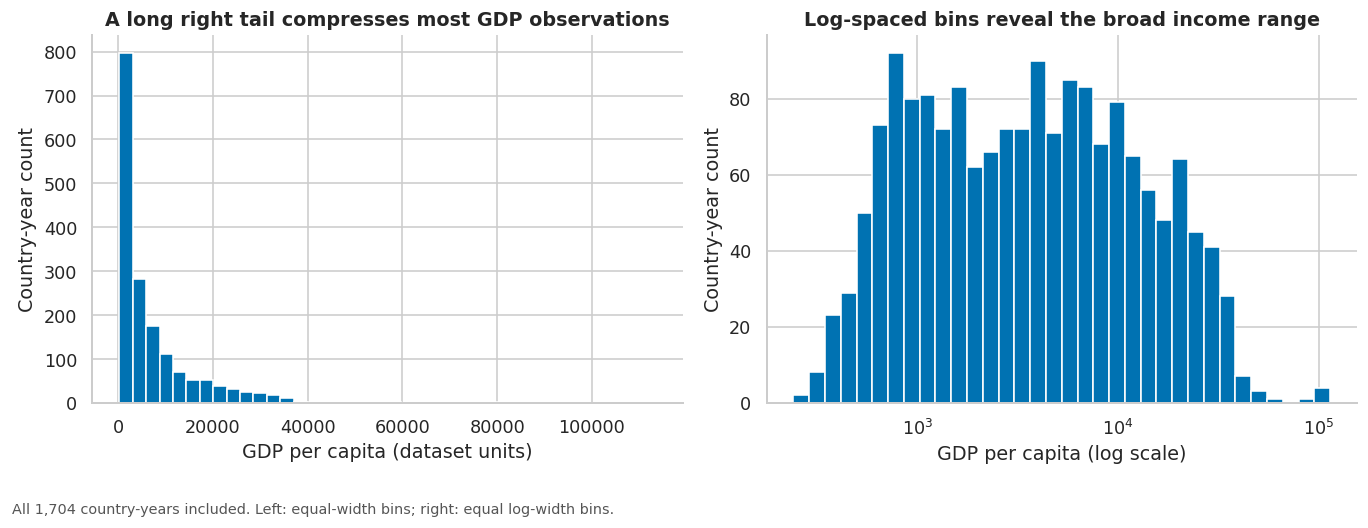

In [6]:
values = df.gdpPercap
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].hist(values, bins=40, color=BLUE, edgecolor='white')
axes[0].set(title='A long right tail compresses most GDP observations',
            xlabel='GDP per capita (dataset units)', ylabel='Country-year count')
edges = np.geomspace(values.min(), values.max(), 35)
axes[1].hist(values, bins=edges, color=BLUE, edgecolor='white')
axes[1].set_xscale('log')
axes[1].set(title='Log-spaced bins reveal the broad income range',
            xlabel='GDP per capita (log scale)', ylabel='Country-year count')
for ax in axes: ax.set_ylim(bottom=0)
finish(fig, 'All 1,704 country-years included. Left: equal-width bins; right: equal log-width bins.')

**Why histograms:** Binned counts reveal skew and concentration. Raw GDP has a long upper tail that squeezes most observations together. The second histogram uses equal log-width bins **as well as** a log x-axis, so equal visual widths represent multiplicative intervals, not equal dollar intervals. This is not merely relabelling the raw histogram. Counts are not density per dollar, and repeated country-years are pooled. A log scale is useful for comparing proportional GDP differences because all values are positive.

## 4. Has the richest-to-poorest gap narrowed?
Define “richest” and “poorest” as the maximum and minimum **country GDP per capita at each year**, not individual wealth. Countries at the extremes may change. Use max/min as a **relative** gap; also report max−min as an absolute gap. Extreme values are sensitive to outliers and data quality.

1952 richest/poorest: [{'country': 'Kuwait', 'gdpPercap': 108382.3529}, {'country': 'Lesotho', 'gdpPercap': 298.8462121}]


,poorest,richest,ratio,absolute_gap
year,,,,
1952,298.85,108382.35,362.67,108083.51
1957,336.00,113523.13,337.87,113187.14
1962,355.20,95458.11,268.74,95102.91
1967,349.00,80894.88,231.79,80545.88
1972,357.00,109347.87,306.30,108990.87
1977,371.00,59265.48,159.75,58894.48
1982,424.00,33693.18,79.47,33269.18
1987,385.00,31540.97,81.92,31155.97
1992,347.00,34932.92,100.67,34585.92


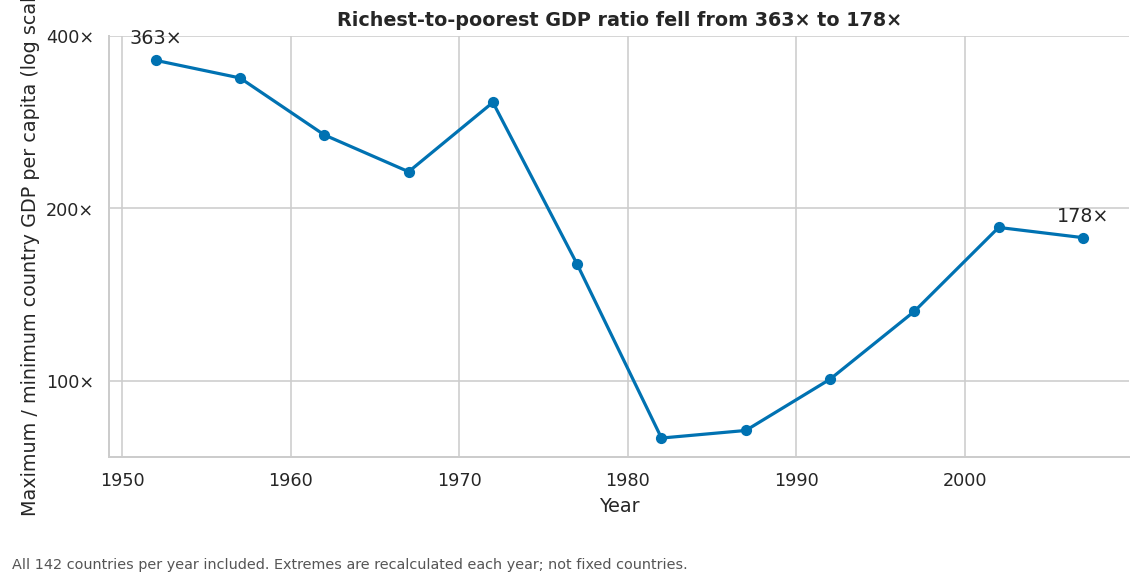

In [7]:
gap = df.groupby('year').gdpPercap.agg(poorest='min', richest='max')
gap['ratio'] = gap.richest / gap.poorest
gap['absolute_gap'] = gap.richest - gap.poorest
display(gap.round(2))
print('1952 richest/poorest:', df[df.year.eq(1952)].loc[[df[df.year.eq(1952)].gdpPercap.idxmax(), df[df.year.eq(1952)].gdpPercap.idxmin()], ['country','gdpPercap']].to_dict('records'))
fig, ax = plt.subplots(figsize=(10, 5.3))
ax.plot(gap.index, gap.ratio, marker='o', color=BLUE, lw=2)
ax.set_yscale('log')
from matplotlib.ticker import NullFormatter
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_yticks([100,200,400]); ax.set_yticklabels(['100×','200×','400×'])
for year in [1952, 2007]:
    ax.annotate(f'{gap.loc[year,"ratio"]:.0f}×', (year,gap.loc[year,'ratio']),
                xytext=(0, 10), textcoords='offset points', ha='center')
ax.set(title=f'Richest-to-poorest GDP ratio fell from {gap.ratio.iloc[0]:.0f}× to {gap.ratio.iloc[-1]:.0f}×',
       xlabel='Year', ylabel='Maximum / minimum country GDP per capita (log scale)')
finish(fig, 'All 142 countries per year included. Extremes are recalculated each year; not fixed countries.')

**Why a line on a log scale:** One gap value per year gives one clear trajectory; a ratio and log axis express multiplicative differences without adding a second y-axis. This is a line, not a zero-truncated bar.

**Answer:** The relative gap narrowed between the endpoints, from about **362.7× to 177.8×**, but not steadily. The absolute max−min gap also fell, from about **108,083.5 to 49,079.6** in the dataset’s GDP units. This conclusion describes the sample’s changing extremes, not the typical-country gap, inequality among individuals, or universal convergence. The exceptional 1952 maximum belongs to Kuwait; a percentile-based comparison would be a useful sensitivity analysis.